![Logo SENATI](../00_Recursos/logo_senati.png)

**SENATI · Laboratorio práctico de IA y visión computacional**  
**Instructor:** Ing. Gunar Castro Iñigo  
**Tecnologías:** Python · OpenCV · NumPy · Matplotlib  
**Modalidad:** demostración → ejecución → interpretación → reto

# Módulo 3 · Segmentación y reconocimiento de patrones

**Propósito:** Separar regiones de interés y reconocer patrones simples por características geométricas.

**Actividad completada por:** COCA CCORPA LORENA ABIGAIL.  
**Fuente:** SEMANA 12 TALLER · SENATI.  
Se conservó el nombre original de este cuaderno. Las imágenes son las suministradas por el taller o transformaciones documentadas de ellas.

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Todos los cuadernos se ejecutan desde su propia carpeta.
RECURSOS = Path('..') / '00_Recursos'
SALIDAS = Path('resultados')
SALIDAS.mkdir(exist_ok=True)

def mostrar(imagen, titulo='Resultado', gris=False):
    """Muestra imágenes en Jupyter sin abrir ventanas externas."""
    plt.figure(figsize=(8, 4))
    if gris:
        plt.imshow(imagen, cmap='gray', vmin=0, vmax=255)
    else:
        plt.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
    plt.title(titulo)
    plt.axis('off')
    plt.show()

print('Entorno listo. OpenCV:', cv2.__version__)

Entorno listo. OpenCV: 4.13.0


## Explicación
**Segmentación:** decidir qué píxeles pertenecen a una región. Su resultado habitual es una **máscara**, una imagen donde blanco significa “pertenece” y negro significa “no pertenece”.

**Reconocimiento de patrones:** utilizar características (forma, tamaño, textura, color) para identificar categorías o regularidades. Nuestra regla geométrica es un clasificador sencillo, no un sistema neuronal entrenado.

### Ejemplo 1: segmentación por intensidad

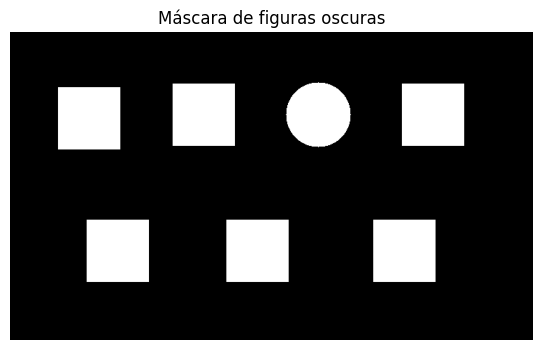

Píxeles pertenecientes a figuras: 51775


In [2]:
imagen = cv2.imread(str(RECURSOS / 'patrones.png'))
gris = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)
# INV: las figuras oscuras pasan a blanco; el fondo claro, a negro.
_, mascara = cv2.threshold(gris, 100, 255, cv2.THRESH_BINARY_INV)
mostrar(mascara, 'Máscara de figuras oscuras', gris=True)
print('Píxeles pertenecientes a figuras:', cv2.countNonZero(mascara))

### Ejemplo 2: reconocimiento de forma por número de vértices

Vertices: 8 | Patron reconocido: Circulo (aprox.)
Vertices: 4 | Patron reconocido: Rectangulo
Vertices: 3 | Patron reconocido: Triangulo


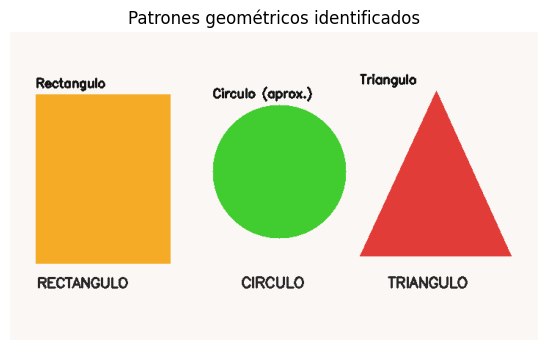

In [3]:
imagen = cv2.imread(str(RECURSOS / 'figuras.png'))
hsv = cv2.cvtColor(imagen, cv2.COLOR_BGR2HSV)
# Segmentación de las figuras saturadas; elimina el fondo casi blanco.
s = hsv[:, :, 1]
_, mascara = cv2.threshold(s, 75, 255, cv2.THRESH_BINARY)
contornos, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
resultado = imagen.copy()
for c in contornos:
    if cv2.contourArea(c) < 1000:
        continue
    perimetro = cv2.arcLength(c, True)
    poligono = cv2.approxPolyDP(c, 0.035 * perimetro, True)
    vertices = len(poligono)
    if vertices == 3:
        nombre = 'Triangulo'
    elif vertices == 4:
        nombre = 'Rectangulo'
    else:
        nombre = 'Circulo (aprox.)'
    x, y, w, h = cv2.boundingRect(c)
    cv2.putText(resultado, nombre, (x, max(20, y-10)), cv2.FONT_HERSHEY_SIMPLEX, .55, (20,20,20), 2)
    print('Vertices:', vertices, '| Patron reconocido:', nombre)
mostrar(resultado, 'Patrones geométricos identificados')

**Limitación importante:** una elipse o una figura irregular puede confundirse con un círculo; con imágenes reales se deben validar las reglas.

**Reto:** añade otra figura en `00_Recursos/figuras.png` y comprueba la clasificación.

**Pregunta oral:** ¿en qué se diferencia la máscara de la etiqueta de categoría?

<div style="background-color:#FFF0A8;color:#463600;border-left:7px solid #D6A400;padding:14px 18px;border-radius:9px;margin:10px 0 16px"><strong>🟨 INICIO DEL DESARROLLO DE LA ACTIVIDAD</strong><br>Desde aquí se realiza el reto y sus comprobaciones. Se conserva el enunciado original y el código se ejecuta en orden.</div>

### Respuestas cortas

**¿Qué pasó al añadir una figura?** La copia con triángulo permitió detectar una figura de tres vértices, sin modificar el recurso original.  
**¿Máscara o categoría?** La máscara marca píxeles; la categoría indica qué figura representan.

## Ejecución del reto del estudiante (actividad resuelta)

In [4]:
# Reto: incorporar una figura triangular en una COPIA de la imagen de prueba.
original=cv2.imread(str(RECURSOS/'figuras.png'))
alto,ancho=original.shape[:2]
extra=np.full((alto+180,ancho,3),255,np.uint8)
extra[:alto,:]=original
pts=np.array([[ancho//2-70,alto+145],[ancho//2,alto+20],[ancho//2+70,alto+145]],np.int32)
cv2.fillPoly(extra,[pts],(0,0,0))
cv2.imwrite(str(SALIDAS/'03_figuras_con_triangulo.png'),extra)
zonas=cv2.cvtColor(extra,cv2.COLOR_BGR2GRAY)
_,binaria=cv2.threshold(zonas,180,255,cv2.THRESH_BINARY_INV)
contornos2,_=cv2.findContours(binaria,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
for c in contornos2:
    if cv2.contourArea(c)>800:
        aprox=cv2.approxPolyDP(c,0.03*cv2.arcLength(c,True),True)
        if len(aprox)==3:print('Nueva figura detectada: triángulo (3 vértices)')
print('Imagen modificada guardada sin cambiar la imagen original del curso.')

Nueva figura detectada: triángulo (3 vértices)
Nueva figura detectada: triángulo (3 vértices)
Imagen modificada guardada sin cambiar la imagen original del curso.


### Conclusión y evaluación

La clasificación por número de vértices depende del umbral y de la forma dibujada; imágenes complejas requerirían reglas y validación adicionales.

**Evidencia:** ejecutar todas las celdas; las imágenes guardadas en `resultados/` muestran el procesamiento. La captura del cuaderno abierto corresponde al estudiante una vez ejecutado en su máquina.